In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [2]:
%pip install pandas numpy matplotlib seaborn

  Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp311-cp311-macosx_11_0_arm64.whl.metadata (5.2 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 24.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 28.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 20.9 MB/s  0:00:00 eta 0:00:01
Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl (270 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 28.2 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp311-cp311-macosx_11_0_arm64.whl (64 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 17.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [seaborn]9/10 [seaborn]ib]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: 

In [4]:
# STEP 2: Locate the dataset files

from pathlib import Path

# Find our project folder
root = Path.cwd()

if root.name == "exploratory_data_analysis":
    root = root.parent

# Locate the datasets folder
data_folder = root / "datasets"

# Display available files
print("Project folder:", root)
print("\nFiles in datasets folder:")

for file in data_folder.iterdir():
    print(file.name)

Project folder: /Users/diyapanwala/code_wifi_indoor_localization

Files in datasets folder:
archive.zip


In [5]:
import zipfile

# Locate the ZIP file
zip_path = data_folder / "archive.zip"

# Check the files inside
with zipfile.ZipFile(zip_path, "r") as zip_file:
    print("Files inside archive.zip:")
    for filename in zip_file.namelist():
        print(filename)

Files inside archive.zip:
TrainingData.csv
ValidationData.csv


In [6]:
# STEP 4: Load the UJIIndoorLoc datasets

import zipfile

with zipfile.ZipFile(zip_path, "r") as zip_file:

    # Find the training and validation files
    train_file = next(
        name for name in zip_file.namelist()
        if name.lower().endswith("trainingdata.csv")
    )

    validation_file = next(
        name for name in zip_file.namelist()
        if name.lower().endswith("validationdata.csv")
    )

    # Load datasets
    train = pd.read_csv(zip_file.open(train_file))
    validation = pd.read_csv(zip_file.open(validation_file))

# Display dataset dimensions
print("Training Dataset:", train.shape)
print("Validation Dataset:", validation.shape)

# Show the first 5 rows
display(train.head())

Training Dataset: (19937, 529)
Validation Dataset: (1111, 529)


,WAP001,WAP002,WAP003,WAP004,WAP005,WAP006,WAP007,WAP008,WAP009,WAP010,...,WAP520,LONGITUDE,LATITUDE,FLOOR,BUILDINGID,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,100,100,100,100,100,100,100,100,100,100,...,100,-7541.2643,4.864921e+06,2,1,106,2,2,23,1371713733
1,100,100,100,100,100,100,100,100,100,100,...,100,-7536.6212,4.864934e+06,2,1,106,2,2,23,1371713691
2,100,100,100,100,100,100,100,-97,100,100,...,100,-7519.1524,4.864950e+06,2,1,103,2,2,23,1371714095
3,100,100,100,100,100,100,100,100,100,100,...,100,-7524.5704,4.864934e+06,2,1,102,2,2,23,1371713807
4,100,100,100,100,100,100,100,100,100,100,...,100,-7632.1436,4.864982e+06,0,0,122,2,11,13,1369909710


In [7]:
# STEP 5: Explore dataset columns and features

# Identify Wi-Fi access point columns
wap_columns = [col for col in train.columns if col.startswith("WAP")]

# Identify other columns
other_columns = [col for col in train.columns if col not in wap_columns]

print("Number of Wi-Fi features:", len(wap_columns))

print("\nOther columns:")
print(other_columns)

print("\nData types:")
print(train.dtypes.value_counts())

print("\nFirst 5 Wi-Fi features:")
display(train[wap_columns[:5]].head())

Number of Wi-Fi features: 520

Other columns:
['LONGITUDE', 'LATITUDE', 'FLOOR', 'BUILDINGID', 'SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']

Data types:
int64      527
float64      2
Name: count, dtype: int64

First 5 Wi-Fi features:


,WAP001,WAP002,WAP003,WAP004,WAP005
0,100,100,100,100,100
1,100,100,100,100,100
2,100,100,100,100,100
3,100,100,100,100,100
4,100,100,100,100,100


In [8]:
# STEP 6: Create building-floor classes

# Combine building and floor into one target label
train["LOCATION_CLASS"] = (
    "B" + train["BUILDINGID"].astype(str)
    + "_F" + train["FLOOR"].astype(str)
)

validation["LOCATION_CLASS"] = (
    "B" + validation["BUILDINGID"].astype(str)
    + "_F" + validation["FLOOR"].astype(str)
)

# Count samples in each class
class_counts = train["LOCATION_CLASS"].value_counts().sort_index()

print("Total number of classes:", len(class_counts))

print("\nSamples per class:")
print(class_counts)

Total number of classes: 13

Samples per class:
LOCATION_CLASS
B0_F0    1059
B0_F1    1356
B0_F2    1443
B0_F3    1391
B1_F0    1368
B1_F1    1484
B1_F2    1396
B1_F3     948
B2_F0    1942
B2_F1    2162
B2_F2    1577
B2_F3    2709
B2_F4    1102
Name: count, dtype: int64


/var/folders/d3/qth_6c357x366bs6ywf8_bw40000gn/T/ipykernel_31942/3776324800.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train["LOCATION_CLASS"] = (
/var/folders/d3/qth_6c357x366bs6ywf8_bw40000gn/T/ipykernel_31942/3776324800.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  validation["LOCATION_CLASS"] = (


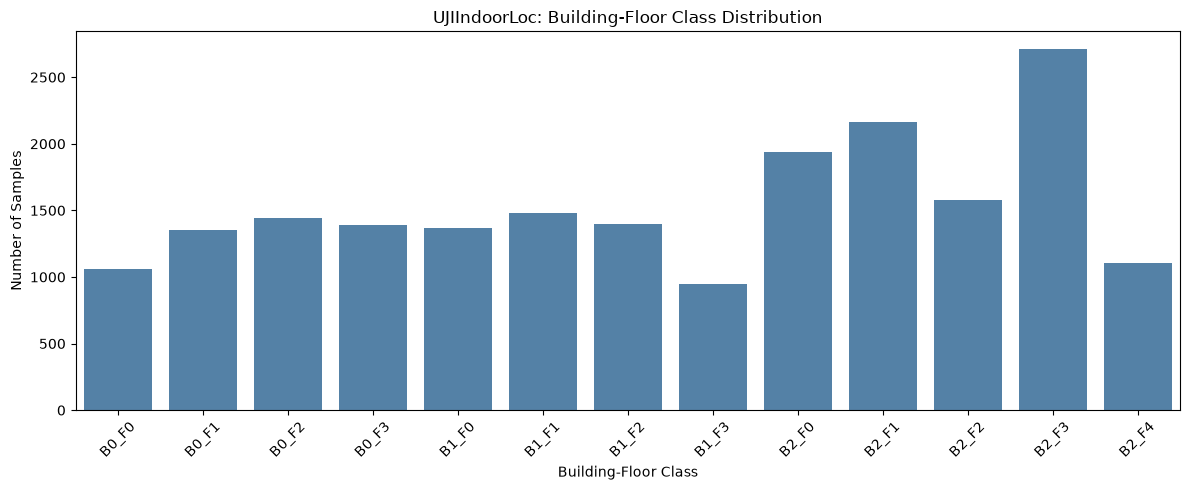

<Figure size 640x480 with 0 Axes>

In [10]:
# STEP 7: Visualize class distribution

plt.figure(figsize=(12, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    color="steelblue"
)

plt.title("UJIIndoorLoc: Building-Floor Class Distribution")
plt.xlabel("Building-Floor Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

plt.savefig(
    root / "exploratory_data_analysis" / "figures" / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

In [11]:
# STEP 8: Missing values and RSSI sparsity

# Check conventional missing values
print("Missing values in training:", train.isnull().sum().sum())
print("Missing values in validation:", validation.isnull().sum().sum())

# Select the 520 Wi-Fi features
wap_data = train[wap_columns]

# Count undetected Wi-Fi signals (100)
undetected = (wap_data == 100).sum().sum()

# Total Wi-Fi measurements
total = wap_data.size

# Calculate sparsity percentage
sparsity = (undetected / total) * 100

print("\nTotal Wi-Fi measurements:", total)
print("Undetected Wi-Fi measurements:", undetected)
print("RSSI sparsity:", round(sparsity, 2), "%")

Missing values in training: 0
Missing values in validation: 0

Total Wi-Fi measurements: 10367240
Undetected Wi-Fi measurements: 10008477
RSSI sparsity: 96.54 %


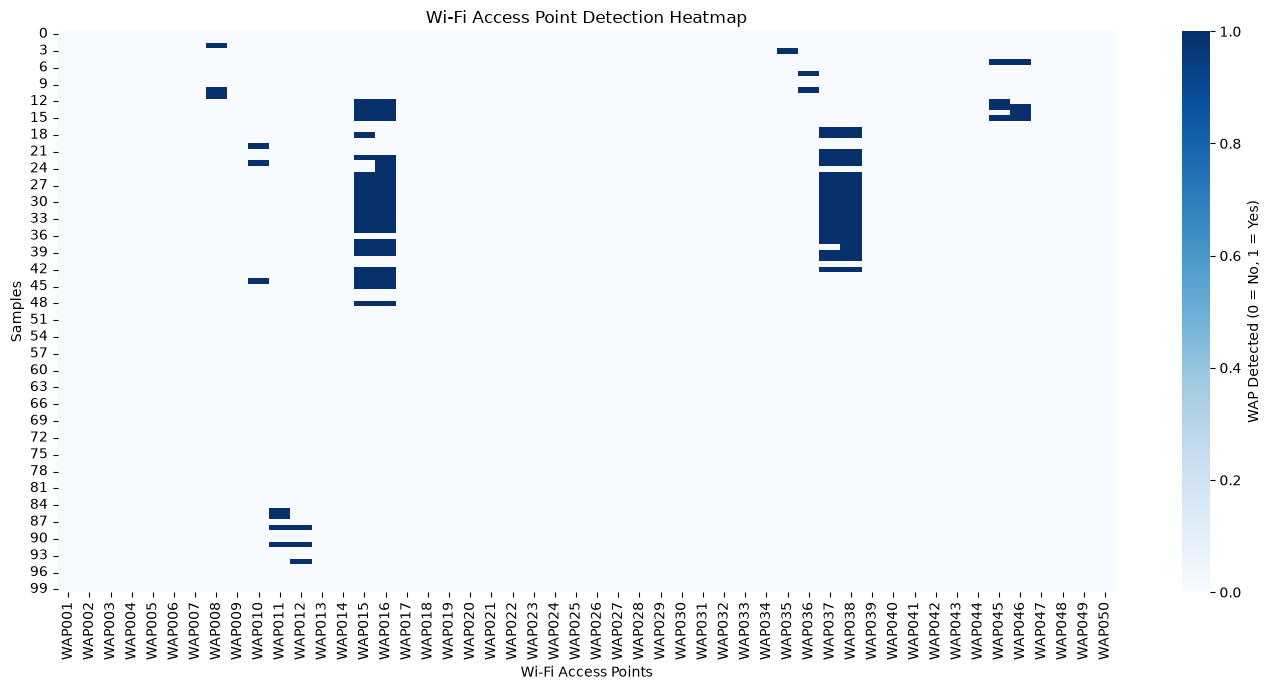

In [12]:
# STEP 9: Wi-Fi detection heatmap

# Select 100 samples and 50 WAP features
sample_data = wap_data.iloc[:100, :50]

# Convert values to detection indicators
# 1 = detected, 0 = undetected
detection_matrix = (sample_data != 100).astype(int)

plt.figure(figsize=(14, 7))

sns.heatmap(
    detection_matrix,
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "WAP Detected (0 = No, 1 = Yes)"}
)

plt.title("Wi-Fi Access Point Detection Heatmap")
plt.xlabel("Wi-Fi Access Points")
plt.ylabel("Samples")

plt.tight_layout()

# Save graph
plt.savefig(
    root / "exploratory_data_analysis" / "figures" / "wap_sparsity_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# STEP 10: Analyze detected WAPs per sample

# Count detected Wi-Fi access points in each sample
detected_waps = (wap_data != 100).sum(axis=1)

# Display summary statistics
print("Detected WAPs per sample:")
print(detected_waps.describe())

# Check samples with no detected Wi-Fi signals
print("\nSamples with 0 detected WAPs:", (detected_waps == 0).sum())

Detected WAPs per sample:
count    19937.000000
mean        17.994834
std          7.333575
min          0.000000
25%         13.000000
50%         17.000000
75%         22.000000
max         51.000000
dtype: float64

Samples with 0 detected WAPs: 76


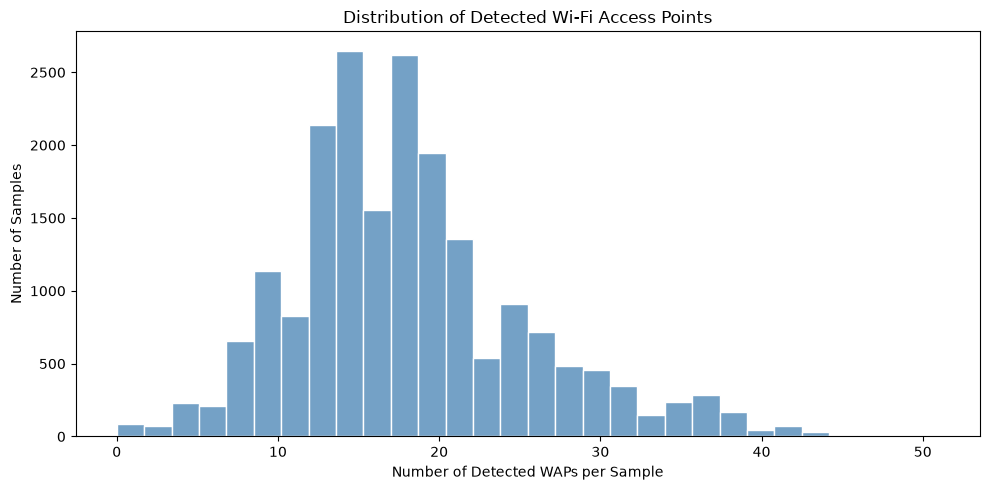

In [14]:
# STEP 11: Distribution of detected WAPs

plt.figure(figsize=(10, 5))

sns.histplot(
    detected_waps,
    bins=30,
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribution of Detected Wi-Fi Access Points")
plt.xlabel("Number of Detected WAPs per Sample")
plt.ylabel("Number of Samples")

plt.tight_layout()

# Save the graph
plt.savefig(
    root / "exploratory_data_analysis" / "figures" / "detected_waps_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# STEP 12: Data quality checks

# Check duplicate rows
print("Duplicate training rows:", train.duplicated().sum())
print("Duplicate validation rows:", validation.duplicated().sum())

# Check number of location classes
print("\nTraining classes:", train["LOCATION_CLASS"].nunique())
print("Validation classes:", validation["LOCATION_CLASS"].nunique())

# Check whether all training classes appear in validation
train_classes = set(train["LOCATION_CLASS"])
validation_classes = set(validation["LOCATION_CLASS"])

print("\nClasses missing from validation:", train_classes - validation_classes)

# Check class distribution in validation
print("\nValidation class distribution:")
print(validation["LOCATION_CLASS"].value_counts().sort_index())

Duplicate training rows: 637
Duplicate validation rows: 0

Training classes: 13
Validation classes: 13

Classes missing from validation: set()

Validation class distribution:
LOCATION_CLASS
B0_F0     78
B0_F1    208
B0_F2    165
B0_F3     85
B1_F0     30
B1_F1    143
B1_F2     87
B1_F3     47
B2_F0     24
B2_F1    111
B2_F2     54
B2_F3     40
B2_F4     39
Name: count, dtype: int64


In [16]:
# STEP 13: Investigate duplicate Wi-Fi fingerprints

# Count repeated Wi-Fi fingerprints
duplicate_waps = train.duplicated(subset=wap_columns).sum()

print("Duplicate Wi-Fi fingerprints:", duplicate_waps)

# Check if identical fingerprints have different location labels
conflicting_labels = (
    train.groupby(wap_columns)["LOCATION_CLASS"]
    .nunique()
)

conflicting_labels = (conflicting_labels > 1).sum()

print("Wi-Fi fingerprints with conflicting location labels:", conflicting_labels)

Duplicate Wi-Fi fingerprints: 852
Wi-Fi fingerprints with conflicting location labels: 1


In [17]:
# STEP 14: Verify duplicate counts

# Count duplicates across all columns
full_duplicates = train.duplicated().sum()

# Count duplicates using only the 520 WAP features
wap_duplicates = train.duplicated(subset=wap_columns).sum()

print("Full-row duplicates:", full_duplicates)
print("WAP-only duplicates:", wap_duplicates)

# Check the relationship between the two counts
print("WAP duplicates >= full duplicates:",
      wap_duplicates >= full_duplicates)

Full-row duplicates: 637
WAP-only duplicates: 852
WAP duplicates >= full duplicates: True


EDA Findings & Recommendations
Dataset Overview
- The UJIIndoorLoc dataset contains 19,937 reference samples and 1,111 validation samples.
- Each original sample contains 529 attributes, including 520 Wi-Fi RSSI features.
- The classification task involves predicting 13 building-floor location classes.

Class Distribution
- All 13 building-floor classes are represented in both datasets.
- The class distribution is uneven, with B2_F3 having the most samples (2,709) and B1_F3 having the fewest (948).
- Macro-F1 should be considered alongside accuracy to account for class imbalance.

Missing Values & Sparsity
- No conventional missing values (NaN) were identified.
- Approximately 96.54% of training RSSI measurements are marked as undetected (100).
- Each sample detects approximately 18 Wi-Fi access points on average.
- 76 samples contain no detected WAPs.

Data Quality
- 637 duplicate full rows were identified.
- 852 rows repeat an earlier Wi-Fi fingerprint.
- The initial analysis found one fingerprint pattern associated with multiple building-floor labels.
- Duplicate and zero-signal samples should be reviewed before preprocessing.

Recommendations
- Replace the undetected-WAP sentinel (100) with an appropriate representation during preprocessing.
- Scale features where appropriate, particularly for KNN and neural networks.
- Use stratified splitting to maintain class proportions.
- Keep the official 1,111-sample validation dataset separate for final testing.
- Evaluate KNN, Random Forest, and Neural Network models using accuracy, Macro-F1, and confusion matrices.
- Check for duplicate fingerprints across development and final test datasets to assess possible data leakage.